# 04 - Forecast and decision

Forecasting the daily demand of each category seven days ahead, with its uncertainty, and using it to decide how much capacity to reserve.

## Part 1. Data and baselines

The series is split by date and two forecasts without a model set the bar.

### Train and test split

The last 56 days are the test period and everything earlier is training data.

In [206]:
import warnings

import holidays
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsforecast import StatsForecast
from statsforecast.models import AutoETS, AutoTheta, SeasonalNaive

warnings.filterwarnings("ignore", category=DeprecationWarning)

series = pd.read_csv("../data/processed/demand_daily.csv", index_col="day", parse_dates=True)

test_days = 56
train = series.iloc[:-test_days]
test = series.iloc[-test_days:]

print(series.shape)
print("train", train.index.min().date(), train.index.max().date(), train.shape)
print("test ", test.index.min().date(), test.index.max().date(), test.shape)

(594, 10)
train 2017-01-05 2018-06-26 (538, 10)
test  2018-06-27 2018-08-21 (56, 10)


### Naive baselines

Two forecasts without a model. The first repeats the same weekday of last week and the second averages the same weekday over the last four weeks. Both are scored with MAE and WAPE on the test period.

In [207]:
naive_7 = series.shift(7)
naive_4w = (series.shift(7) + series.shift(14) + series.shift(21) + series.shift(28)) / 4

def evaluate(pred):
    """Compare a forecast against the test period, per category."""
    pred = pred.loc[test.index]
    err = (test - pred).abs()
    return pd.DataFrame({"mae": err.mean(), "wape": err.sum() / test.sum()})

res_7 = evaluate(naive_7)
res_4w = evaluate(naive_4w)

summary = pd.DataFrame({
    "mae_7": res_7["mae"], "wape_7": res_7["wape"],
    "mae_4w": res_4w["mae"], "wape_4w": res_4w["wape"],
}).round(2)
summary.reset_index(names="category")

,category,mae_7,wape_7,mae_4w,wape_4w
0,auto,4.80,0.38,4.55,0.36
1,bed_bath_table,10.05,0.43,8.45,0.36
2,computers_accessories,5.36,0.35,5.23,0.35
3,furniture_decor,7.89,0.48,6.55,0.40
4,garden_tools,4.64,0.77,3.22,0.54
5,health_beauty,10.61,0.36,8.51,0.29
6,housewares,7.21,0.34,7.26,0.34
7,sports_leisure,6.11,0.37,4.83,0.29
8,telephony,4.38,0.49,4.31,0.48
9,watches_gifts,6.71,0.40,5.70,0.34


## Part 2. A first model

A global LightGBM model on lag features, compared with the best baseline on the last 56 days.

### Long table with lag features

One row per day and category, with lags from 7 to 28 days, rolling means and the day of the week. Every feature uses data from at least seven days earlier, matching the forecast horizon.

In [208]:
long = (
    series.rename_axis(columns="category")
    .stack()
    .rename("units")
    .reset_index()
    .sort_values(["category", "day"])
    .reset_index(drop=True)
)

g = long.groupby("category")["units"]
for lag in (7, 14, 21, 28):
    long[f"lag_{lag}"] = g.shift(lag)
long["mean_7"] = g.transform(lambda s: s.shift(7).rolling(7).mean())
long["mean_28"] = g.transform(lambda s: s.shift(7).rolling(28).mean())
long["dow"] = long["day"].dt.day_of_week

long["category"] = long["category"].astype("category")
long = long.dropna().reset_index(drop=True)
long.shape

(5600, 10)

### First LightGBM model

A single model for all categories, trained on the days before the test period with the absolute error as loss, the same quantity WAPE measures.

In [209]:
test_start = test.index.min()
features = ["category", "lag_7", "lag_14", "lag_21", "lag_28", "mean_7", "mean_28", "dow"]

train_df = long[long["day"] < test_start]
test_df = long[long["day"] >= test_start]

model = lgb.LGBMRegressor(objective="l1", n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1)
model.fit(train_df[features], train_df["units"])

test_df = test_df.assign(pred=model.predict(test_df[features]))

err = (test_df["units"] - test_df["pred"]).abs()
by_cat = test_df["category"]
res_lgb = pd.DataFrame({
    "mae_lgb": err.groupby(by_cat, observed=True).mean(),
    "wape_lgb": err.groupby(by_cat, observed=True).sum()
    / test_df.groupby("category", observed=True)["units"].sum(),
})

compare = res_4w.rename(columns={"mae": "mae_4w", "wape": "wape_4w"}).join(res_lgb).round(2)
total_4w = (test - naive_4w.loc[test.index]).abs().sum().sum() / test.sum().sum()
total_lgb = err.sum() / test_df["units"].sum()
print("overall WAPE, baseline 4w:", round(total_4w, 3), "| LightGBM:", round(total_lgb, 3))
compare.reset_index(names="category")

overall WAPE, baseline 4w: 0.352 | LightGBM: 0.351


,category,mae_4w,wape_4w,mae_lgb,wape_lgb
0,auto,4.55,0.36,4.58,0.36
1,bed_bath_table,8.45,0.36,8.18,0.35
2,computers_accessories,5.23,0.35,4.61,0.30
3,furniture_decor,6.55,0.40,5.92,0.36
4,garden_tools,3.22,0.54,2.99,0.50
5,health_beauty,8.51,0.29,9.87,0.34
6,housewares,7.26,0.34,9.06,0.43
7,sports_leisure,4.83,0.29,4.14,0.25
8,telephony,4.31,0.48,3.98,0.45
9,watches_gifts,5.70,0.34,5.06,0.30


## Part 3. Improving the first model

Three hypotheses tested one at a time, the Black Friday spike in the lag features, a model too flexible for the data, and a level shift that trees cannot extrapolate. A rolling backtest over three periods is introduced to judge them.

### Removing the Black Friday weeks

Training without the rows from 2017-11-24 to 2017-12-29, whose lag features contain the Black Friday spike.

In [210]:
def fit_eval(train_df, params=None):
    """Train on train_df, return the overall WAPE on the test period."""
    params = params or dict(objective="l1", n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1)
    model = lgb.LGBMRegressor(**params)
    model.fit(train_df[features], train_df["units"])
    out = test_df.assign(pred=model.predict(test_df[features]))
    err = (out["units"] - out["pred"]).abs()
    return err.sum() / out["units"].sum()

before_test = long["day"] < test_start
black_friday = (long["day"] >= "2017-11-24") & (long["day"] <= "2017-12-29")

pd.DataFrame({"wape": {
    "all training days": fit_eval(long[before_test]),
    "without Black Friday": fit_eval(long[before_test & ~black_friday]),
}}).round(3).reset_index(names="training")

,training,wape
0,all training days,0.351
1,without Black Friday,0.342


### Smaller models

The same comparison with fewer and smaller trees.

In [211]:
train_clean = long[before_test & ~black_friday]

configs = {
    "default":   dict(objective="l1", n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1),
    "small":     dict(objective="l1", n_estimators=150, learning_rate=0.05, num_leaves=8, min_child_samples=40, random_state=42, verbose=-1),
    "very small": dict(objective="l1", n_estimators=100, learning_rate=0.05, num_leaves=4, min_child_samples=60, random_state=42, verbose=-1),
}

pd.DataFrame({"wape": {name: fit_eval(train_clean, params) for name, params in configs.items()}}).round(3).reset_index(names="model")

,model,wape
0,default,0.342
1,small,0.334
2,very small,0.334


### Rolling backtest

Three consecutive test periods of 56 days. Each period is predicted with a model trained only on earlier data.

In [212]:
long["baseline"] = long[["lag_7", "lag_14", "lag_21", "lag_28"]].mean(axis=1)

def wape(actual, pred):
    """Total absolute error divided by total units."""
    return (actual - pred).abs().sum() / actual.sum()

last_day = long["day"].max()

def split_period(data, k, cal_days=0):
    """Train, calibration and test rows of backtest period k, where 0 is the most recent.

    Each test period has 56 days. Training stops before the calibration window, which sits
    right before the test period, and always excludes the Black Friday weeks.
    """
    test_end = last_day - pd.Timedelta(days=56 * k)
    test_begin = test_end - pd.Timedelta(days=55)
    cal_begin = test_begin - pd.Timedelta(days=cal_days)
    tr = data[(data["day"] < cal_begin) & ~black_friday]
    cal = data[(data["day"] >= cal_begin) & (data["day"] < test_begin)]
    te = data[(data["day"] >= test_begin) & (data["day"] <= test_end)]
    return tr, cal, te

scores = {"baseline 4w": [], "lgb default": [], "lgb very small": []}
starts = []
for k in range(3):
    tr, _, te = split_period(long, k)
    starts.append(te["day"].min().date())

    scores["baseline 4w"].append(wape(te["units"], te["baseline"]))
    for name, label in (("default", "lgb default"), ("very small", "lgb very small")):
        m = lgb.LGBMRegressor(**configs[name]).fit(tr[features], tr["units"])
        scores[label].append(wape(te["units"], m.predict(te[features])))

backtest = pd.DataFrame(scores, index=["period_1", "period_2", "period_3"]).T
backtest["mean"] = backtest.mean(axis=1)
print("period starts:", starts)
backtest.round(3).reset_index(names="model")

period starts: [datetime.date(2018, 6, 27), datetime.date(2018, 5, 2), datetime.date(2018, 3, 7)]


,model,period_1,period_2,period_3,mean
0,baseline 4w,0.352,0.404,0.300,0.352
1,lgb default,0.342,0.378,0.290,0.337
2,lgb very small,0.334,0.366,0.271,0.324


### Demand relative to the recent level

Training on units divided by the 28-day mean and rescaling the prediction back to units.

In [213]:
very_small = configs["very small"]

rel = long.copy()
for col in ["lag_7", "lag_14", "lag_21", "lag_28", "mean_7"]:
    rel[col] = rel[col] / rel["mean_28"]
rel["target"] = rel["units"] / rel["mean_28"]

def run_backtest(data, params, relative=False):
    """Return the WAPE of each of the 3 backtest periods, most recent first."""
    scores = []
    for k in range(3):
        tr, _, te = split_period(data, k)
        y = tr["target"] if relative else tr["units"]
        model = lgb.LGBMRegressor(**params).fit(tr[features], y)
        pred = model.predict(te[features])
        if relative:
            pred = pred * te["mean_28"]
        scores.append(wape(te["units"], pred))
    return [round(float(s), 3) for s in scores]

tab = pd.DataFrame({
    "raw units": run_backtest(long, very_small),
    "relative": run_backtest(rel, very_small, relative=True),
}, index=["period_1", "period_2", "period_3"]).T
tab["mean"] = tab.mean(axis=1)
tab.round(3).reset_index(names="target")

,target,period_1,period_2,period_3,mean
0,raw units,0.334,0.366,0.271,0.324
1,relative,0.329,0.371,0.293,0.331


## Part 4. Other variants and benchmarks

Further changes to the model and the classical methods a forecasting study is expected to compare against. None changes the result, which points to the limit of what the history of each category explains.

### Poisson loss and blend with the baseline

The small model with a Poisson loss, and a 50/50 average of the model with the baseline, on the same three periods.

In [214]:
def backtest_scores(data, params, blend=None):
    """WAPE per backtest period, optionally blending the model with the baseline."""
    scores = []
    for k in range(3):
        tr, _, te = split_period(data, k)
        model = lgb.LGBMRegressor(**params).fit(tr[features], tr["units"])
        pred = model.predict(te[features])
        if blend is not None:
            pred = blend * pred + (1 - blend) * te["baseline"].to_numpy()
        scores.append(wape(te["units"], pred))
    return [round(s, 3) for s in scores]

poisson = {**very_small, "objective": "poisson"}
variants = {
    "very small": backtest_scores(long, very_small),
    "poisson": backtest_scores(long, poisson),
    "blend 50/50": backtest_scores(long, very_small, blend=0.5),
    "poisson blend 50/50": backtest_scores(long, poisson, blend=0.5),
}
tab = pd.DataFrame(variants, index=["period_1", "period_2", "period_3"]).T
tab["mean"] = tab.mean(axis=1)
tab.round(3).reset_index(names="model")

,model,period_1,period_2,period_3,mean
0,very small,0.334,0.366,0.271,0.324
1,poisson,0.338,0.368,0.272,0.326
2,blend 50/50,0.336,0.377,0.277,0.330
3,poisson blend 50/50,0.336,0.375,0.276,0.329


### Classical benchmarks

Seasonal naive, ETS and Theta fitted per category with statsforecast. Within each period the models are refit every seven days and forecast the next seven, so the average horizon is four days, shorter than the seven days of the lag features, which favors them.

In [215]:
sf_data = long[["day", "category", "units"]].rename(
    columns={"day": "ds", "category": "unique_id", "units": "y"}
)
sf_data["unique_id"] = sf_data["unique_id"].astype(str)

def classical_scores(models):
    """WAPE per backtest period for statsforecast models, 7-day horizon, refit every 7 days."""
    scores = {m.alias if hasattr(m, "alias") else type(m).__name__: [] for m in models}
    for k in range(3):
        _, _, te_rows = split_period(long, k)
        test_begin, test_end = te_rows["day"].min(), te_rows["day"].max()
        preds = []
        for start in pd.date_range(test_begin, test_end, freq="7D"):
            tr = sf_data[sf_data["ds"] < start]
            sf = StatsForecast(models=models, freq="D", n_jobs=1)
            preds.append(sf.forecast(df=tr, h=7))
        pred = pd.concat(preds).reset_index()
        te = sf_data[(sf_data["ds"] >= test_begin) & (sf_data["ds"] <= test_end)]
        merged = te.merge(pred, on=["unique_id", "ds"])
        for name in scores:
            scores[name].append(round(wape(merged["y"], merged[name]), 3))
    return pd.DataFrame(scores, index=["period_1", "period_2", "period_3"]).T

classical = classical_scores([
    SeasonalNaive(season_length=7),
    AutoETS(season_length=7),
    AutoTheta(season_length=7),
])
classical["mean"] = classical.mean(axis=1).round(3)
classical.reset_index(names="model")

,model,period_1,period_2,period_3,mean
0,SeasonalNaive,0.407,0.411,0.350,0.389
1,AutoETS,0.332,0.368,0.297,0.332
2,AutoTheta,0.322,0.358,0.288,0.323


### Calendar features

Brazilian national holidays, day of month and month added to the feature list.

In [216]:
br_holidays = holidays.Brazil(years=[2017, 2018])
long["holiday"] = long["day"].dt.date.isin(br_holidays).astype(int)
long["day_of_month"] = long["day"].dt.day
long["month"] = long["day"].dt.month

features_cal = features + ["holiday", "day_of_month", "month"]

def backtest_with(feature_list):
    """WAPE per backtest period for the small model with the given features."""
    scores = []
    for k in range(3):
        tr, _, te = split_period(long, k)
        model = lgb.LGBMRegressor(**very_small).fit(tr[feature_list], tr["units"])
        scores.append(round(wape(te["units"], model.predict(te[feature_list])), 3))
    return scores

tab = pd.DataFrame({
    "current features": backtest_with(features),
    "with calendar": backtest_with(features_cal),
}, index=["period_1", "period_2", "period_3"]).T
tab["mean"] = tab.mean(axis=1)
print("holiday days in data:", long.groupby("day")["holiday"].first().sum())
tab.round(3).reset_index(names="features")

holiday days in data: 12


,features,period_1,period_2,period_3,mean
0,current features,0.334,0.366,0.271,0.324
1,with calendar,0.344,0.362,0.270,0.325


### Fewer features

The three lags the model rarely uses are removed to check whether they were adding noise.

In [217]:
reduced = ["category", "lag_7", "mean_7", "mean_28", "dow"]
tab = pd.DataFrame({
    "all features": backtest_with(features),
    "reduced features": backtest_with(reduced),
}, index=["period_1", "period_2", "period_3"]).T
tab["mean"] = tab.mean(axis=1)
tab.round(3).reset_index(names="features")

,features,period_1,period_2,period_3,mean
0,all features,0.334,0.366,0.271,0.324
1,reduced features,0.334,0.365,0.273,0.324


## Part 5. Uncertainty

From a single number to a band. Quantile models, how often the band contains the actual demand, and how to widen it when it is too narrow.

### Quantile forecasts

The same model trained to predict the 10th, 50th and 90th percentiles of demand, checked on the last test period.

In [218]:
quantiles = [0.1, 0.5, 0.9]

out = test_df[["day", "category", "units"]].copy()
for q in quantiles:
    params = {**very_small, "objective": "quantile", "alpha": q}
    model = lgb.LGBMRegressor(**params).fit(train_clean[features], train_clean["units"])
    out[f"q{int(q * 100)}"] = model.predict(test_df[features])

pd.DataFrame([{
    "below_q10": (out["units"] < out["q10"]).mean(),
    "above_q90": (out["units"] > out["q90"]).mean(),
    "inside": ((out["units"] >= out["q10"]) & (out["units"] <= out["q90"])).mean(),
}]).round(3)

,below_q10,above_q90,inside
0,0.096,0.155,0.748


### Band coverage across periods

Share of days below the 10th and above the 90th percentile in each backtest period.

In [219]:
def quantile_coverage(data, k, params):
    """Share of days below q10 and above q90 for backtest period k."""
    tr, _, te = split_period(data, k)
    bounds = {}
    for q in (0.1, 0.9):
        model = lgb.LGBMRegressor(**{**params, "objective": "quantile", "alpha": q})
        model.fit(tr[features], tr["units"])
        bounds[q] = model.predict(te[features])
    below = (te["units"] < bounds[0.1]).mean()
    above = (te["units"] > bounds[0.9]).mean()
    return {"test_start": te["day"].min().date(), "below_q10": below,
            "above_q90": above, "inside": 1 - below - above}

pd.DataFrame([quantile_coverage(long, k, very_small) for k in range(3)]).round(3)

,test_start,below_q10,above_q90,inside
0,2018-06-27,0.096,0.155,0.748
1,2018-05-02,0.164,0.157,0.679
2,2018-03-07,0.121,0.091,0.788


### Calibrating the band

The band is widened by the amount it fell short in a 56-day calibration window placed right before each test period. The model behind the band is trained only on data before that window, so the calibration errors are out of sample and the coverage before widening differs slightly from the previous table.

In [220]:
def calibrated_bounds(data, k, params, cal_days=56, level=0.8, relative=False):
    """Band for backtest period k. Returns the test rows, the 10-90 bounds and the widening of each row.

    With relative=True the widening is proportional to the 28-day mean of each row, so a
    category with more units gets a wider adjustment.
    """
    tr, cal, te = split_period(data, k, cal_days)

    models = {}
    for q in (0.1, 0.9):
        model = lgb.LGBMRegressor(**{**params, "objective": "quantile", "alpha": q})
        models[q] = model.fit(tr[features], tr["units"])

    scale_cal = cal["mean_28"].to_numpy() if relative else 1.0
    scale_te = te["mean_28"].to_numpy() if relative else np.ones(len(te))

    y_cal = cal["units"].to_numpy()
    lo_cal = models[0.1].predict(cal[features])
    hi_cal = models[0.9].predict(cal[features])
    score = np.maximum(lo_cal - y_cal, y_cal - hi_cal) / scale_cal
    n = len(score)
    adjustment = np.quantile(score, min(1.0, np.ceil((n + 1) * level) / n)) * scale_te

    lo = models[0.1].predict(te[features])
    hi = models[0.9].predict(te[features])
    return te, lo, hi, adjustment

def calibrated_band(data, k, params):
    """Coverage of the band before and after widening in backtest period k."""
    te, lo, hi, adjustment = calibrated_bounds(data, k, params)
    y = te["units"].to_numpy()
    return {
        "test_start": te["day"].min().date(),
        "adjustment": adjustment.mean(),
        "inside_before": ((y >= lo) & (y <= hi)).mean(),
        "inside_after": ((y >= lo - adjustment) & (y <= hi + adjustment)).mean(),
    }

pd.DataFrame([calibrated_band(long, k, very_small) for k in range(3)]).round(3)

,test_start,adjustment,inside_before,inside_after
0,2018-06-27,2.060,0.723,0.823
1,2018-05-02,0.172,0.689,0.698
2,2018-03-07,3.636,0.700,0.864


### Coverage by category

The calibrated band pooled over the three periods and split by category, sorted by average daily units. The fixed widening is one number in units for all categories. The scaled widening is proportional to the 28-day mean of each category.

In [221]:
pooled = []
for relative in (False, True):
    for k in range(3):
        te, lo, hi, adjustment = calibrated_bounds(long, k, very_small, relative=relative)
        y = te["units"].to_numpy()
        pooled.append(pd.DataFrame({
            "category": te["category"].to_numpy(),
            "units": y,
            "inside_before": (y >= lo) & (y <= hi),
            "inside_after": (y >= lo - adjustment) & (y <= hi + adjustment),
            "relative": relative,
        }))
pooled = pd.concat(pooled)

coverage_by_category = pd.DataFrame({
    "mean_units": pooled[~pooled["relative"]].groupby("category", observed=True)["units"].mean(),
    "inside_before": pooled[~pooled["relative"]].groupby("category", observed=True)["inside_before"].mean(),
    "inside_fixed": pooled[~pooled["relative"]].groupby("category", observed=True)["inside_after"].mean(),
    "inside_scaled": pooled[pooled["relative"]].groupby("category", observed=True)["inside_after"].mean(),
}).sort_values("mean_units", ascending=False)
coverage_by_category.round(3).reset_index()

,category,mean_units,inside_before,inside_fixed,inside_scaled
0,health_beauty,26.113,0.565,0.649,0.690
1,bed_bath_table,24.583,0.655,0.768,0.804
2,housewares,18.488,0.732,0.804,0.798
3,sports_leisure,17.875,0.732,0.804,0.798
4,furniture_decor,17.250,0.732,0.786,0.792
5,watches_gifts,17.143,0.661,0.780,0.762
6,computers_accessories,16.345,0.714,0.833,0.839
7,auto,11.506,0.732,0.845,0.798
8,telephony,9.095,0.744,0.857,0.804
9,garden_tools,7.595,0.774,0.827,0.821


### Pinball loss

The standard metric for quantile forecasts, lower is better. Raw and calibrated model quantiles are compared with the baseline shifted by the same calibrated amount.

In [222]:
def pinball(y, pred, q):
    """Average pinball loss of a quantile forecast."""
    diff = y - pred
    return np.mean(np.maximum(q * diff, (q - 1) * diff))

def pinball_scores(data, k, params, cal_days=56):
    """Pinball loss per quantile in backtest period k, raw, calibrated and baseline."""
    tr, cal, te = split_period(data, k, cal_days)
    y_cal = cal["units"].to_numpy()
    y = te["units"].to_numpy()
    n = len(cal)

    rows = {"test_start": te["day"].min().date()}
    for q in (0.1, 0.5, 0.9):
        rank = min(1.0, np.ceil((n + 1) * q) / n)
        model = lgb.LGBMRegressor(**{**params, "objective": "quantile", "alpha": q})
        model.fit(tr[features], tr["units"])
        pred = model.predict(te[features])
        adjustment = np.quantile(y_cal - model.predict(cal[features]), rank)
        adjustment_base = np.quantile(y_cal - cal["baseline"].to_numpy(), rank)
        name = f"q{int(q * 100)}"
        rows[f"raw_{name}"] = pinball(y, pred, q)
        rows[f"calibrated_{name}"] = pinball(y, pred + adjustment, q)
        rows[f"baseline_{name}"] = pinball(y, te["baseline"].to_numpy() + adjustment_base, q)
    return rows

pin = pd.DataFrame([pinball_scores(long, k, very_small) for k in range(3)]).set_index("test_start")
pin.loc["mean"] = pin.mean()
pin.round(3).reset_index()

,test_start,raw_q10,calibrated_q10,baseline_q10,raw_q50,calibrated_q50,baseline_q50,raw_q90,calibrated_q90,baseline_q90
0,2018-06-27,1.099,1.114,1.408,2.811,2.834,2.980,1.444,1.358,1.359
1,2018-05-02,1.235,1.213,1.590,2.972,2.971,3.256,1.460,1.477,1.702
2,2018-03-07,1.026,1.014,1.353,2.711,2.579,2.813,1.634,1.368,1.309
3,mean,1.120,1.114,1.450,2.832,2.795,3.017,1.513,1.401,1.457


## Part 6. Diagnostics

What the final model does and where it fails.

### Forecast and actual demand

Quantile forecasts for the last 56 days in two large and two small categories, using the uncalibrated band.

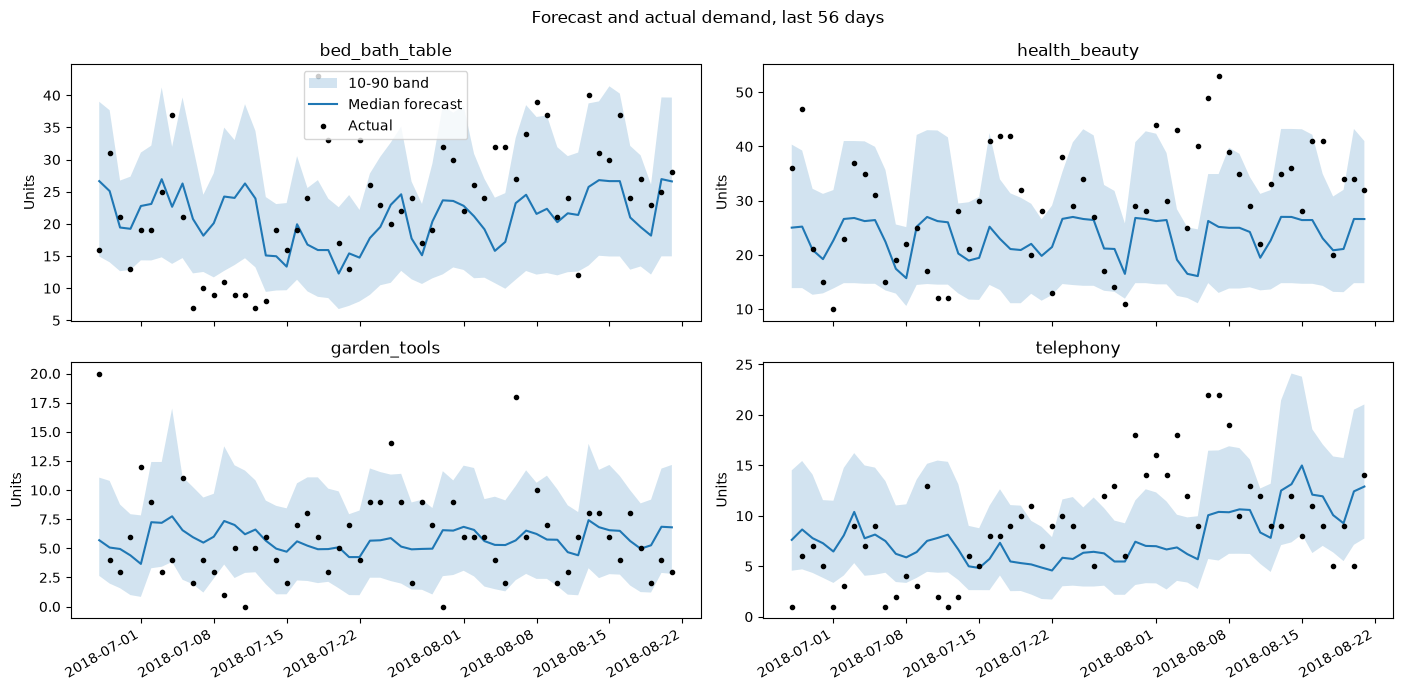

In [223]:
final_train = long[(long["day"] < test_start) & ~black_friday]
preds = test_df[["day", "category", "units"]].copy()
for q in (0.1, 0.5, 0.9):
    model = lgb.LGBMRegressor(**{**very_small, "objective": "quantile", "alpha": q})
    model.fit(final_train[features], final_train["units"])
    preds[f"q{int(q * 100)}"] = model.predict(test_df[features])

fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
for ax, cat in zip(axes.flat, ["bed_bath_table", "health_beauty", "garden_tools", "telephony"]):
    p = preds[preds["category"] == cat].set_index("day")
    ax.fill_between(p.index, p["q10"], p["q90"], alpha=0.2, label="10-90 band")
    ax.plot(p.index, p["q50"], label="Median forecast")
    ax.plot(p.index, p["units"], "k.", label="Actual")
    ax.set_title(cat)
    ax.set_ylabel("Units")
axes[0, 0].legend()
fig.suptitle("Forecast and actual demand, last 56 days")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### Feature importance

Number of splits in which each feature is used by the median model.

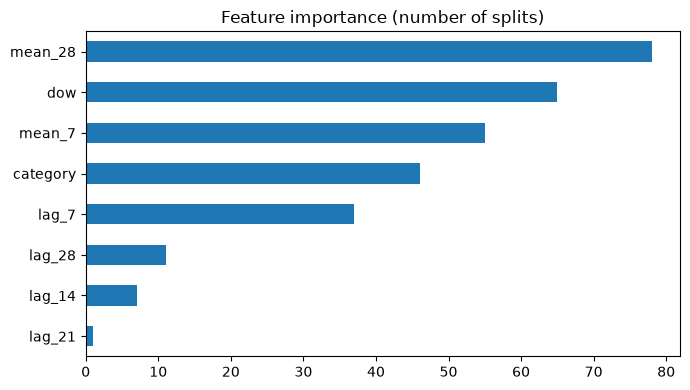

In [224]:
model = lgb.LGBMRegressor(**very_small).fit(final_train[features], final_train["units"])
importance = pd.Series(model.feature_importances_, index=features).sort_values()
importance.plot.barh(figsize=(7, 4), title="Feature importance (number of splits)")
plt.tight_layout()
plt.show()

### Error analysis

Bias and MAE of the median forecast on the last 56 days, by category and by weekday. A positive bias means the forecast is above actual demand.

In [225]:
preds["error"] = preds["q50"] - preds["units"]
preds["weekday"] = preds["day"].dt.day_of_week

by_category = preds.groupby("category", observed=True).agg(
    bias=("error", "mean"),
    mae=("error", lambda e: e.abs().mean()),
    mean_units=("units", "mean"),
).round(2)

by_weekday = preds.groupby("weekday").agg(
    bias=("error", "mean"),
    mae=("error", lambda e: e.abs().mean()),
    mean_units=("units", "mean"),
).round(2)
by_weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

print("overall bias:", round(preds["error"].mean(), 2))
display(by_category.reset_index())
display(by_weekday.reset_index(names="weekday"))

overall bias: -1.66


,category,bias,mae,mean_units
0,auto,-1.75,4.43,12.77
1,bed_bath_table,-2.11,7.72,23.16
2,computers_accessories,-0.19,4.76,15.14
3,furniture_decor,-0.97,5.80,16.30
4,garden_tools,-0.24,2.95,6.00
5,health_beauty,-6.02,9.39,29.36
6,housewares,-3.48,7.29,21.11
7,sports_leisure,-0.72,4.33,16.70
8,telephony,-1.05,4.23,8.95
9,watches_gifts,-0.03,5.21,16.96


,weekday,bias,mae,mean_units
0,Mon,-1.36,6.12,18.51
1,Tue,-2.12,6.15,19.29
2,Wed,-2.48,6.93,18.86
3,Thu,-2.39,5.72,18.66
4,Fri,-1.44,5.07,15.44
5,Sat,-0.62,3.45,12.34
6,Sun,-1.18,5.84,13.41


### Error persistence

Autocorrelation of the daily forecast error at lags 1 and 7 for each category and for the daily total, over the three backtest periods in sequence. Values above 0.15 in absolute terms are unlikely to come from chance with this many days.

In [226]:
errors = []
for k in (2, 1, 0):
    tr, _, te = split_period(long, k)
    model = lgb.LGBMRegressor(**very_small).fit(tr[features], tr["units"])
    errors.append(pd.DataFrame({
        "day": te["day"].to_numpy(),
        "category": te["category"].astype(str).to_numpy(),
        "error": te["units"].to_numpy() - model.predict(te[features]),
    }))
errors_by_day = pd.concat(errors).pivot(index="day", columns="category", values="error")

def autocorr(x, lag):
    """Correlation of the error with the error lag days earlier."""
    x = x - x.mean()
    return float((x[lag:] * x[:-lag]).sum() / (x * x).sum())

series_to_check = {name: errors_by_day[name].to_numpy() for name in errors_by_day.columns}
series_to_check["all categories"] = errors_by_day.sum(axis=1).to_numpy()
persistence = pd.DataFrame({
    name: {"lag_1": autocorr(x, 1), "lag_7": autocorr(x, 7)} for name, x in series_to_check.items()
}).T

print("days:", len(errors_by_day), "| rough 95% bound without autocorrelation:", round(2 / np.sqrt(len(errors_by_day)), 3))
persistence.round(2).reset_index(names="series")

days: 168 | rough 95% bound without autocorrelation: 0.154


,series,lag_1,lag_7
0,auto,0.30,-0.06
1,bed_bath_table,0.31,-0.14
2,computers_accessories,0.41,-0.00
3,furniture_decor,0.36,-0.05
4,garden_tools,0.21,-0.03
5,health_beauty,0.51,0.12
6,housewares,0.41,0.03
7,sports_leisure,0.30,-0.11
8,telephony,0.43,0.10
9,watches_gifts,0.56,0.14


## Part 7. Decision

Turning the forecast into a capacity reservation with asymmetric costs, and comparing it with reserving the baseline.

### Reservation decision

Capacity is reserved before demand is known. Each unit short costs Cu and each unit left idle costs Co, and the best reservation is the demand quantile at Cu / (Cu + Co). Three policies are compared, the baseline forecast, the baseline plus a calibrated buffer and the calibrated quantile of the model. The costs are assumed values, 4 and 1 in the main run and varied in the next section.

In [227]:
CU, CO = 4.0, 1.0

def cost(y, capacity, cu, co):
    """Total cost of reserving the given capacity when demand turns out to be y."""
    return (cu * np.maximum(y - capacity, 0) + co * np.maximum(capacity - y, 0)).sum()

def decision_costs(data, k, params, cu, co, cal_days=56, relative=False):
    """Cost of three reservation policies in backtest period k.

    With relative=True both calibrated policies use a widening proportional to the 28-day mean.
    """
    level = cu / (cu + co)
    tr, cal, te = split_period(data, k, cal_days)

    model = lgb.LGBMRegressor(**{**params, "objective": "quantile", "alpha": level})
    model.fit(tr[features], tr["units"])

    scale_cal = cal["mean_28"].to_numpy() if relative else 1.0
    scale_te = te["mean_28"].to_numpy() if relative else np.ones(len(te))

    n = len(cal)
    rank = min(1.0, np.ceil((n + 1) * level) / n)
    y_cal = cal["units"].to_numpy()
    y = te["units"].to_numpy()

    capacity_baseline = te["baseline"].to_numpy()
    buffer = np.quantile((y_cal - cal["baseline"].to_numpy()) / scale_cal, rank) * scale_te
    capacity_buffer = capacity_baseline + buffer

    adjustment = np.quantile((y_cal - model.predict(cal[features])) / scale_cal, rank) * scale_te
    capacity_model = model.predict(te[features]) + adjustment

    return {
        "test_start": te["day"].min().date(),
        "baseline": cost(y, capacity_baseline, cu, co),
        "baseline_buffer": cost(y, capacity_buffer, cu, co),
        "model": cost(y, capacity_model, cu, co),
    }

res = pd.DataFrame([decision_costs(long, k, very_small, CU, CO) for k in range(3)])
res["saving_vs_buffer"] = 1 - res["model"] / res["baseline_buffer"]
res.round(3)

,test_start,baseline,baseline_buffer,model,saving_vs_buffer
0,2018-06-27,9105.25,5977.051,5764.138,0.036
1,2018-05-02,8781.25,7007.049,6368.531,0.091
2,2018-03-07,6607.00,5648.250,5686.556,-0.007


### Sensitivity to the cost ratio

The same policies with the costs as parameters, summed over the three backtest periods.

In [228]:
rows = []
for cu in (1, 2, 4, 9):
    per_period = pd.DataFrame([decision_costs(long, k, very_small, cu, 1.0) for k in range(3)])
    total = per_period[["baseline", "baseline_buffer", "model"]].sum()
    rows.append({
        "cu_over_co": cu,
        "critical_ratio": cu / (cu + 1),
        "buffer_vs_baseline": 1 - total["baseline_buffer"] / total["baseline"],
        "model_vs_buffer": 1 - total["model"] / total["baseline_buffer"],
    })
pd.DataFrame(rows).round(3)

,cu_over_co,critical_ratio,buffer_vs_baseline,model_vs_buffer
0,1,0.500,-0.035,0.073
1,2,0.667,0.041,0.055
2,4,0.800,0.239,0.044
3,9,0.900,0.501,0.038


### Widening proportional to category level

The decision policies with the widening scaled by the 28-day mean of each category, against the fixed widening, summed over the three backtest periods. The last column compares the scaled model with the fixed buffer, which is the cheaper of the two buffers.

In [229]:
rows = []
for cu in (1, 2, 4, 9):
    fixed = pd.DataFrame([decision_costs(long, k, very_small, cu, 1.0) for k in range(3)])
    scaled = pd.DataFrame([decision_costs(long, k, very_small, cu, 1.0, relative=True) for k in range(3)])
    cols = ["baseline_buffer", "model"]
    fixed, scaled = fixed[cols].sum(), scaled[cols].sum()
    rows.append({
        "cu_over_co": cu,
        "buffer_scaled_vs_fixed": 1 - scaled["baseline_buffer"] / fixed["baseline_buffer"],
        "model_scaled_vs_fixed": 1 - scaled["model"] / fixed["model"],
        "model_vs_buffer_scaled": 1 - scaled["model"] / scaled["baseline_buffer"],
        "model_scaled_vs_buffer_fixed": 1 - scaled["model"] / fixed["baseline_buffer"],
    })
pd.DataFrame(rows).round(3)

,cu_over_co,buffer_scaled_vs_fixed,model_scaled_vs_fixed,model_vs_buffer_scaled,model_scaled_vs_buffer_fixed
0,1,-0.019,0.002,0.092,0.075
1,2,-0.042,0.002,0.096,0.057
2,4,-0.070,0.011,0.117,0.054
3,9,-0.087,0.019,0.132,0.056


## Findings

The best naive baseline, the average of the same weekday over the last four weeks, has a WAPE of 0.352 on the last 56 days. A first LightGBM model trained with the absolute error as loss ties it, 0.351 against 0.352. Removing the Black Friday weeks from training and using a smaller model bring the average over three backtest periods to 0.324 against 0.352 for the baseline, and the model is better than the baseline in each of the three periods.

Five variants (relative target, Poisson loss, two blends with the baseline, calendar features) did not improve on 0.324, and removing the lags beyond 7 days leaves it unchanged. Theta and ETS land within 0.01 of LightGBM while seeing fresher data, since their average horizon is four days against seven. Three different approaches reaching a similar error suggests the limit of what the history of each category explains. LightGBM is kept because it gives quantiles with the same pipeline.

The model follows the weekly pattern and the recent level, as the feature importance shows. In the last test period its median forecast is 10% below actual demand overall and 20% below in health_beauty, the largest category. Daily errors correlate with the error of the previous day, 0.2 to 0.6 by category and 0.7 for the daily total, and only weakly with the error of a week earlier, at most 0.14 by category and 0.19 for the total. The misses come in runs, which is consistent with level shifts that the lag features see seven days late.

Calibration raises the coverage of the 10-90 band from 70% to 79.5% on average against a target of 80%, but in the second period it stays at 70%. A fixed widening covers 65% of days in health_beauty and 86% in telephony. A widening proportional to the 28-day mean of each category narrows that to between 76% and 84%, except for health_beauty at 69%. On pinball loss the model beats the calibrated baseline at the 10th and 50th percentiles in the three periods, and on average at the 90th, where the baseline is better in one period.

For the reservation decision, a calibrated buffer over the baseline costs 3.5% more when a shortage and an idle unit cost the same, and saves 4%, 24% and 50% when a shortage costs two, four and nine times more. Against the buffer with fixed widening, which is cheaper than the proportional one, the model with proportional widening saves between 5% and 8% in every ratio tested. With the fixed widening and a ratio of four, the buffer was cheaper than the model in one of the three periods.

Health_beauty is still under-covered and is the first category to inspect. The same three periods were used to choose and to report the model, so these figures should be confirmed on new data.